<a href="https://colab.research.google.com/github/panarisivalentino-pixel/prediccion-rendimiento-agricola-argentina/blob/main/notebooks/07_modelado_supervisado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelado supervisado del rendimiento agrícola (kg/ha) en Argentina

**Variable objetivo:** `rendimiento_kgxha`  
**Dataset:** `df_recortado.csv` — producción y rendimiento de cultivos por provincia y departamento (1981–2024), integrados con variables climáticas anuales (NASA POWER: temperatura, radiación, humedad y precipitación).

Este notebook parte de un dataset ya limpio y explorado; se centra exclusivamente en el **modelado**: preparación para modelado, entrenamiento y comparación de cinco algoritmos de regresión, optimización de hiperparámetros, interpretabilidad y conclusiones.

**Estructura**
1. Preparación de datos para modelado
2. Selección y justificación de algoritmos
3. Optimización de modelos
4. Interpretabilidad y análisis de resultados
5. Comparativa final de modelos
6. Conclusión final

In [ ]:
import warnings, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score, RandomizedSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import lightgbm as lgb, shap

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
pd.options.display.float_format = '{:,.3f}'.format

df = pd.read_csv('df_recortado.csv')
print('Dimensiones:', df.shape)
df.head()

Dimensiones: (111417, 17)


,cultivo,año,provincia,provincia_id,departamento,departamento_id,superficie_sembrada_ha,superficie_cosechada_ha,produccion_tm,rendimiento_kgxha,T2M,T2M_MAX,T2M_MIN,ALLSKY_SFC_SW_DWN,RH2M,precip_total_mm,meses_con_dato
0,ajo,1981,Buenos Aires,6,Bahía Blanca,6056,10,10,39,3900,15.380,28.650,2.540,0.000,71.830,805.900,12.000
1,ajo,1981,Buenos Aires,6,Balcarce,6063,275,275,990,3600,15.380,28.650,2.540,0.000,71.830,805.900,12.000
2,ajo,1981,Buenos Aires,6,Coronel de Marina Leonardo Rosales,6182,10,10,38,3800,15.380,28.650,2.540,0.000,71.830,805.900,12.000
3,ajo,1981,Buenos Aires,6,Coronel Pringles,6196,4,4,18,4500,15.380,28.650,2.540,0.000,71.830,805.900,12.000
4,ajo,1981,Buenos Aires,6,General Pueyrredón,6357,3,3,10,3333,15.380,28.650,2.540,0.000,71.830,805.900,12.000


## 1. Preparación de datos para modelado

### 1.1 Identificación de variables predictoras

El dataset tiene 17 columnas. Se clasifican de la siguiente forma:

| Grupo | Variables | Decisión |
|---|---|---|
| **Objetivo** | `rendimiento_kgxha` | Variable a predecir |
| **Categóricas geográficas** | `provincia` (23 niveles), `departamento` (397 niveles) | Se codifican |
| **Categórica agronómica** | `cultivo` (41 niveles) | Se codifica |
| **Temporal** | `año` | Numérica (captura tendencia tecnológica) |
| **Superficie** | `superficie_sembrada_ha`, `superficie_cosechada_ha` | Numéricas, transformadas en log |
| **Climáticas** | `T2M`, `T2M_MAX`, `T2M_MIN`, `ALLSKY_SFC_SW_DWN`, `RH2M`, `precip_total_mm` | Numéricas |
| **Descartadas** | `produccion_tm` | **Fuga de información (leakage):** el rendimiento se calcula como `produccion_tm × 1000 / superficie_cosechada_ha`; incluirla haría trivial la predicción |
| | `provincia_id`, `departamento_id` | Redundantes con las categóricas |
| | `meses_con_dato` | Constante (= 12) |

Además se construyen tres variables derivadas con sentido agronómico: `ratio_cosechada` (superficie cosechada / sembrada, proxy de pérdida de lotes), `amplitud_termica` (`T2M_MAX − T2M_MIN`) y las superficies en escala logarítmica (distribución muy asimétrica).

Dos ajustes mínimos previos al modelado (no son EDA, son requisitos del modelado):
- Filas con `superficie_cosechada_ha = 0`: el rendimiento no está definido (no hubo cosecha); se excluyen del problema de regresión.
- `ALLSKY_SFC_SW_DWN = 0` en 1981–1983 es un código de dato faltante de la fuente (la radiación solar anual nunca es 0); se recodifica como `NaN` y se imputa con la mediana del conjunto de entrenamiento.

In [ ]:
n0 = len(df)
df = df[df['superficie_cosechada_ha'] > 0].copy()
print(f'Filas sin cosecha excluidas: {n0-len(df):,}  →  filas para modelado: {len(df):,}')

df['ALLSKY_SFC_SW_DWN'] = df['ALLSKY_SFC_SW_DWN'].replace(0, np.nan)
df['log_sup_sembrada']  = np.log1p(df['superficie_sembrada_ha'])
df['log_sup_cosechada'] = np.log1p(df['superficie_cosechada_ha'])
df['ratio_cosechada']   = (df['superficie_cosechada_ha'] / df['superficie_sembrada_ha'].replace(0, np.nan)).clip(upper=1.5)
df['amplitud_termica']  = df['T2M_MAX'] - df['T2M_MIN']

CAT_OHE   = ['cultivo', 'provincia']
CAT_TE    = ['departamento']
NUM       = ['año', 'log_sup_sembrada', 'log_sup_cosechada', 'ratio_cosechada',
             'T2M', 'T2M_MAX', 'T2M_MIN', 'amplitud_termica', 'ALLSKY_SFC_SW_DWN', 'RH2M', 'precip_total_mm']
CLIMA     = ['T2M', 'T2M_MAX', 'T2M_MIN', 'amplitud_termica', 'ALLSKY_SFC_SW_DWN', 'RH2M', 'precip_total_mm']
TARGET    = 'rendimiento_kgxha'

X = df[CAT_OHE + CAT_TE + NUM]
y = df[TARGET]
print('Predictoras crudas:', X.shape[1])

Filas sin cosecha excluidas: 6,969  →  filas para modelado: 104,448
Predictoras crudas: 14


### 1.2 Transformación de la variable objetivo

El rendimiento tiene una distribución **fuertemente asimétrica**: la mediana es ~2.200 kg/ha, pero cultivos como caña de azúcar, banana o cebolla superan los 15.000–40.000 kg/ha. Entrenar sobre la escala original haría que los errores de esos pocos cultivos dominen la función de pérdida. Por eso los modelos se entrenan sobre `log1p(rendimiento)` y **todas las métricas se reportan en la escala original (kg/ha)** deshaciendo la transformación con `expm1`. Esta es una práctica estándar en regresión con objetivos positivos y de cola larga.

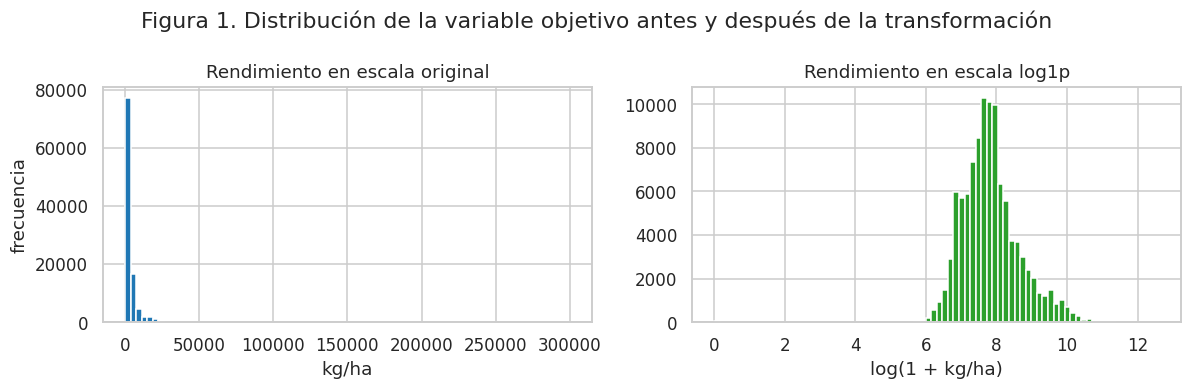

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(y, bins=80, color='tab:blue'); ax[0].set_title('Rendimiento en escala original'); ax[0].set_xlabel('kg/ha'); ax[0].set_ylabel('frecuencia')
ax[1].hist(np.log1p(y), bins=80, color='tab:green'); ax[1].set_title('Rendimiento en escala log1p'); ax[1].set_xlabel('log(1 + kg/ha)')
plt.suptitle('Figura 1. Distribución de la variable objetivo antes y después de la transformación'); plt.tight_layout(); plt.show()
y_log = np.log1p(y)

### 1.3 División entrenamiento / prueba (80 / 20)

Aunque en regresión la estratificación no es obligatoria, se estratifica por **`cultivo`** para garantizar que los 41 cultivos aparezcan en ambas particiones en la misma proporción. Esto es importante porque hay cultivos muy poco frecuentes (jojoba, tung, cártamo) que de otro modo podrían quedar ausentes del conjunto de prueba.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y_log, test_size=0.20, random_state=SEED, stratify=X['cultivo'])
print(f'Train: {X_train.shape[0]:,} filas  |  Test: {X_test.shape[0]:,} filas')
chk = pd.concat([X_train['cultivo'].value_counts(normalize=True).rename('train'),
                 X_test['cultivo'].value_counts(normalize=True).rename('test')], axis=1)
print('Máxima diferencia de proporción por cultivo entre train y test: {:.4f}'.format((chk['train']-chk['test']).abs().max()))

Train: 83,558 filas  |  Test: 20,890 filas
Máxima diferencia de proporción por cultivo entre train y test: 0.0000


### 1.4 Codificación de variables categóricas

- **`cultivo` y `provincia`** (41 y 23 niveles): *one-hot encoding*. Cardinalidad manejable y permite que los modelos lineales tengan un coeficiente interpretable por cultivo/provincia.
- **`departamento`** (397 niveles): *target encoding* con validación cruzada interna (`sklearn.preprocessing.TargetEncoder`). Un one-hot generaría ~400 columnas dispersas; el target encoding reemplaza cada departamento por el rendimiento (log) medio esperado, suavizado hacia la media global, y usa *K-fold* internamente para no filtrar el valor de la propia fila. Se ajusta **solo con los datos de entrenamiento**.

### 1.5 Estandarización

Los modelos lineales y con regularización (Regresión Lineal, Ridge) son sensibles a la escala, por lo que se encapsulan en un `Pipeline` con `StandardScaler`. Los modelos basados en árboles son invariantes a transformaciones monótonas de las variables, así que reciben los datos sin escalar. La imputación de `ALLSKY_SFC_SW_DWN` se hace con la mediana de entrenamiento.

### 1.6 Desbalanceo de datos

Al ser un problema de regresión no existe desbalanceo de clases en sentido estricto. Sí existen dos formas de desbalanceo relevantes, tratadas así:
1. **Desbalanceo de categorías** (maíz tiene 13.000 filas, jojoba menos de 100): se mitiga con la estratificación del split y con el suavizado del target encoding, que evita sobreajustar departamentos con pocas observaciones.
2. **Desbalanceo del objetivo** (cola larga hacia rendimientos altos): se mitiga con la transformación logarítmica de la sección 1.2.

In [ ]:
def preparar(X_tr, X_te, y_tr):
    '''Codifica y prepara matrices. Todo se ajusta con el set de entrenamiento.'''
    Xtr = pd.get_dummies(X_tr, columns=CAT_OHE, dtype=float)
    Xte = pd.get_dummies(X_te, columns=CAT_OHE, dtype=float).reindex(columns=Xtr.columns, fill_value=0.0)
    te = TargetEncoder(target_type='continuous', cv=5, random_state=SEED)
    Xtr['departamento'] = te.fit_transform(X_tr[CAT_TE], y_tr)[:, 0]
    Xte['departamento'] = te.transform(X_te[CAT_TE])[:, 0]
    med = Xtr.median()
    return Xtr.fillna(med), Xte.fillna(med)

Xtr, Xte = preparar(X_train, X_test, y_train)
print('Matriz final de entrenamiento:', Xtr.shape, '| prueba:', Xte.shape)
print('Columnas:', list(Xtr.columns[:12]), '...')

Matriz final de entrenamiento: (83558, 76) | prueba: (20890, 76)
Columnas: ['departamento', 'año', 'log_sup_sembrada', 'log_sup_cosechada', 'ratio_cosechada', 'T2M', 'T2M_MAX', 'T2M_MIN', 'amplitud_termica', 'ALLSKY_SFC_SW_DWN', 'RH2M', 'precip_total_mm'] ...


## 2. Selección y justificación de algoritmos

Se entrenan **cinco** modelos de regresión. Para cada uno se presenta la justificación teórica, los hiperparámetros elegidos y los resultados (MAE, RMSE y R² en entrenamiento y prueba, en kg/ha), además del tiempo de entrenamiento. La función `evaluar` centraliza el cálculo de métricas.

In [ ]:
resultados = {}   # nombre -> dict de métricas
modelos    = {}   # nombre -> modelo ajustado
preds_test = {}   # nombre -> predicciones (kg/ha) sobre test

def metricas(y_true_log, y_pred_log):
    yt, yp = np.expm1(y_true_log), np.expm1(np.clip(y_pred_log, 0, 14))
    return dict(MAE=mean_absolute_error(yt, yp), RMSE=np.sqrt(mean_squared_error(yt, yp)), R2=r2_score(yt, yp))

def evaluar(nombre, modelo, Xtr=Xtr, Xte=Xte):
    t0 = time.time(); modelo.fit(Xtr, y_train); t = time.time() - t0
    m_tr = metricas(y_train, modelo.predict(Xtr)); m_te = metricas(y_test, modelo.predict(Xte))
    resultados[nombre] = {'MAE train': m_tr['MAE'], 'RMSE train': m_tr['RMSE'], 'R² train': m_tr['R2'],
                          'MAE test': m_te['MAE'], 'RMSE test': m_te['RMSE'], 'R² test': m_te['R2'], 'Tiempo (s)': t}
    modelos[nombre] = modelo; preds_test[nombre] = np.expm1(modelo.predict(Xte))
    fila = pd.DataFrame(resultados[nombre], index=[nombre])
    display(fila.style.format({'MAE train':'{:,.0f}','RMSE train':'{:,.0f}','MAE test':'{:,.0f}','RMSE test':'{:,.0f}',
                               'R² train':'{:.4f}','R² test':'{:.4f}','Tiempo (s)':'{:.1f}'}))
    return modelo

### 2.1 Regresión Lineal (modelo base)

**Justificación.** Es el punto de partida obligado: asume una relación lineal y aditiva entre predictoras y objetivo (en escala log, esto equivale a efectos multiplicativos sobre el rendimiento, lo cual es razonable en agronomía: un cultivo dado rinde "X % más" en una provincia que en otra). Es rápido, totalmente interpretable (un coeficiente por variable) y establece el piso de desempeño que los modelos complejos deben superar para justificar su costo.

**Hiperparámetros.** No tiene hiperparámetros relevantes; solo se estandarizan las variables para que los coeficientes sean comparables.  
**Complejidad.** O(n·p²) por la solución de mínimos cuadrados; despreciable para este tamaño.

In [ ]:
lr = evaluar('Regresión Lineal', make_pipeline(StandardScaler(), LinearRegression()))

,MAE train,RMSE train,R² train,MAE test,RMSE test,R² test,Tiempo (s)
Regresión Lineal,"1,023","2,470",0.7864,"1,020","2,243",0.8205,0.4


### 2.2 Ridge (regresión lineal regularizada) — modelo adicional a elección

**Justificación.** Con 76 columnas, muchas de ellas dummies correlacionadas y variables climáticas colineales (`T2M`, `T2M_MAX`, `T2M_MIN`, `amplitud_termica`), la regresión lineal ordinaria puede tener coeficientes inestables. Ridge añade una penalización L2 que reduce la varianza de los coeficientes, mantiene la interpretabilidad y suele mejorar levemente la generalización. Se elige sobre Lasso porque no queremos eliminar cultivos/provincias completos del modelo, solo estabilizar.

**Hiperparámetros.** `alpha = 1.0` (valor por defecto, penalización moderada); los datos están estandarizados para que la penalización afecte a todas las variables por igual.  
**Complejidad.** Igual a la regresión lineal (solución cerrada).

In [ ]:
ridge = evaluar('Ridge', make_pipeline(StandardScaler(), Ridge(alpha=1.0, random_state=SEED)))

,MAE train,RMSE train,R² train,MAE test,RMSE test,R² test,Tiempo (s)
Ridge,"1,023","2,470",0.7864,"1,020","2,243",0.8205,0.1


### 2.3 Random Forest Regressor

**Justificación.** El rendimiento agrícola depende de **interacciones** fuertes (el efecto de la precipitación no es el mismo para arroz que para trigo; el efecto de la temperatura depende de la latitud) y de relaciones **no lineales con umbrales** (estrés hídrico o térmico a partir de cierto valor). Los árboles capturan esto de forma natural sin necesidad de especificar términos de interacción. Random Forest promedia cientos de árboles entrenados con *bootstrap* y subconjuntos aleatorios de variables, lo que reduce la varianza y lo hace muy robusto a outliers y a variables irrelevantes.

**Hiperparámetros iniciales.**
- `n_estimators = 200`: suficiente para que el promedio se estabilice; más árboles solo aumentan el costo linealmente.
- `max_features = 0.5`: usar la mitad de las variables en cada división descorrelaciona los árboles (hay muchas dummies, por lo que 1/3 sería demasiado restrictivo).
- `min_samples_leaf = 2`: evita hojas con una única observación, reduciendo sobreajuste.
- `max_depth = None`: los árboles crecen libremente; el bagging controla la varianza.

**Complejidad.** O(T · n · log n · m) con T árboles y m variables por división. Es el modelo más costoso en memoria (almacena todos los árboles) y no paraleliza en esta máquina de un solo núcleo.

In [ ]:
rf = evaluar('Random Forest', RandomForestRegressor(n_estimators=200, max_features=0.5, min_samples_leaf=2, n_jobs=-1, random_state=SEED))

,MAE train,RMSE train,R² train,MAE test,RMSE test,R² test,Tiempo (s)
Random Forest,262,"1,116",0.9564,484,"1,280",0.9416,104.9


### 2.4 LightGBM (gradient boosting optimizado)

**Justificación.** El *gradient boosting* construye árboles de forma secuencial, cada uno corrigiendo los residuos del anterior, lo que suele dar la mejor precisión en datos tabulares heterogéneos como este (mezcla de categóricas de alta cardinalidad, numéricas continuas y temporales). LightGBM usa histogramas de las variables y crecimiento *leaf-wise*, lo que lo hace un orden de magnitud más rápido que el boosting tradicional y permite entrenar cientos de árboles en segundos. Además maneja valores faltantes de forma nativa. Se eligió sobre XGBoost por su menor tiempo de entrenamiento con un desempeño equivalente.

**Hiperparámetros iniciales.**
- `n_estimators = 600` y `learning_rate = 0.05`: muchos árboles pequeños con paso chico; combinación estándar que balancea precisión y sobreajuste.
- `num_leaves = 63`: complejidad moderada por árbol (equivale a profundidad ~6).
- `subsample = 0.8`, `colsample_bytree = 0.8`: muestreo de filas y columnas para regularizar.
- `min_child_samples = 20` (defecto): evita hojas con pocas observaciones.

**Complejidad.** O(T · n · bins); muy eficiente. Es el modelo más rápido de los basados en árboles.

In [ ]:
lgbm = evaluar('LightGBM', lgb.LGBMRegressor(n_estimators=600, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                                             colsample_bytree=0.8, random_state=SEED, verbose=-1))

,MAE train,RMSE train,R² train,MAE test,RMSE test,R² test,Tiempo (s)
LightGBM,538,"1,518",0.9193,602,"1,430",0.9270,4.2


### 2.5 Gradient Boosting tradicional (scikit-learn)

**Justificación.** Se incluye la implementación clásica de *gradient boosting* (Friedman, 2001) como contraste con LightGBM: mismo principio (árboles secuenciales sobre residuos) pero con árboles de profundidad fija, sin histogramas ni crecimiento leaf-wise. Permite verificar si la ganancia de LightGBM proviene del algoritmo base o de sus optimizaciones, y sirve como segundo *ensemble* de boosting para el análisis de correlación entre predicciones.

**Hiperparámetros.**
- `n_estimators = 200`, `learning_rate = 0.1`, `max_depth = 5`: configuración conservadora dado su costo (cada árbol se construye de forma exacta, no por histogramas).
- `subsample = 0.8`: *stochastic gradient boosting*, reduce varianza y tiempo.

**Complejidad.** O(T · n · log n · p); en la práctica es el más lento por número de árboles porque evalúa todas las divisiones posibles.

In [ ]:
gbr = evaluar('Gradient Boosting', GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, subsample=0.8, random_state=SEED))

,MAE train,RMSE train,R² train,MAE test,RMSE test,R² test,Tiempo (s)
Gradient Boosting,748,"1,822",0.8838,775,"1,693",0.8978,52.5


### 2.6 Comparación inicial respecto al modelo base

,MAE train,RMSE train,R² train,MAE test,RMSE test,R² test,Tiempo (s),Δ MAE test vs base (%),Δ R² test vs base,Gap R² (train−test)
Regresión Lineal,"1,023","2,470",0.7864,"1,020","2,243",0.8205,0.4,+0.0,+0.0000,-0.0341
Ridge,"1,023","2,470",0.7864,"1,020","2,243",0.8205,0.1,+0.0,-0.0000,-0.0341
Random Forest,262,"1,116",0.9564,484,"1,280",0.9416,104.9,-52.6,+0.1210,0.0148
LightGBM,538,"1,518",0.9193,602,"1,430",0.9270,4.2,-41.0,+0.1065,-0.0077
Gradient Boosting,748,"1,822",0.8838,775,"1,693",0.8978,52.5,-24.0,+0.0772,-0.0140


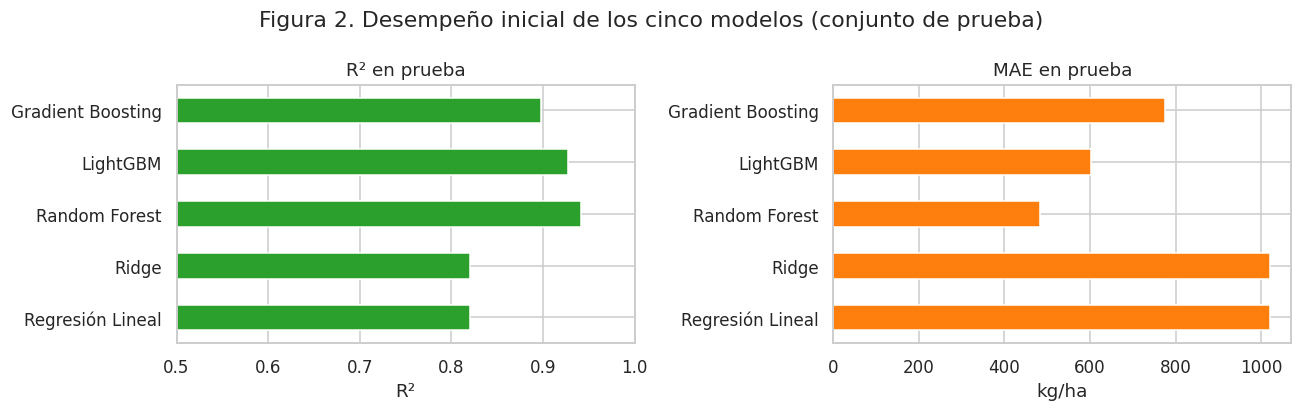

In [ ]:
tabla_inicial = pd.DataFrame(resultados).T
base = tabla_inicial.loc['Regresión Lineal']
tabla_inicial['Δ MAE test vs base (%)']  = (tabla_inicial['MAE test'] / base['MAE test'] - 1) * 100
tabla_inicial['Δ R² test vs base']       = tabla_inicial['R² test'] - base['R² test']
tabla_inicial['Gap R² (train−test)']     = tabla_inicial['R² train'] - tabla_inicial['R² test']
fmt = {c: '{:,.0f}' for c in ['MAE train','RMSE train','MAE test','RMSE test']}
fmt.update({'R² train':'{:.4f}','R² test':'{:.4f}','Tiempo (s)':'{:.1f}','Δ MAE test vs base (%)':'{:+.1f}','Δ R² test vs base':'{:+.4f}','Gap R² (train−test)':'{:.4f}'})
display(tabla_inicial.style.format(fmt).background_gradient(subset=['R² test'], cmap='Greens'))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
tabla_inicial['R² test'].plot.barh(ax=ax[0], color='tab:green'); ax[0].set_title('R² en prueba'); ax[0].set_xlim(0.5, 1); ax[0].set_xlabel('R²')
tabla_inicial['MAE test'].plot.barh(ax=ax[1], color='tab:orange'); ax[1].set_title('MAE en prueba'); ax[1].set_xlabel('kg/ha')
plt.suptitle('Figura 2. Desempeño inicial de los cinco modelos (conjunto de prueba)'); plt.tight_layout(); plt.show()

**Lectura.** Los modelos lineales explican una parte importante de la varianza gracias a las dummies de cultivo y provincia (que absorben las diferencias de nivel entre cultivos), pero los modelos basados en árboles reducen el error absoluto de forma sustancial al capturar interacciones cultivo × clima × región. Random Forest y LightGBM son los dos mejores en la evaluación inicial; el gap entre R² de entrenamiento y prueba de Random Forest es el mayor (típico del bagging con árboles sin restricción de profundidad), lo que se revisará con las learning curves. Estos dos modelos pasan a la etapa de optimización.

## 3. Optimización de modelos

### 3.1 Búsqueda de hiperparámetros con `RandomizedSearchCV` (K-Fold, k = 5)

Se optimizan los dos modelos con mejor desempeño inicial: **Random Forest** y **LightGBM**. Se usa búsqueda aleatoria (más eficiente que la grilla exhaustiva cuando hay varios hiperparámetros continuos) con validación cruzada de 5 particiones y R² como métrica. Para que la búsqueda sea computacionalmente viable en esta máquina (1 núcleo), se realiza sobre una **submuestra estratificada de 30.000 filas de entrenamiento** y luego el mejor conjunto de hiperparámetros se **reentrena sobre el 100 % del conjunto de entrenamiento**.

In [ ]:
idx_sub = X_train.sample(30_000, random_state=SEED).index
Xsub, ysub = Xtr.loc[idx_sub], y_train.loc[idx_sub]
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

espacio_rf = {'n_estimators': [100, 150], 'max_depth': [12, 18, 24, None], 'max_features': [0.3, 0.5, 0.7],
              'min_samples_leaf': [1, 2, 4, 8], 'min_samples_split': [2, 5, 10]}
t0 = time.time()
rs_rf = RandomizedSearchCV(RandomForestRegressor(n_jobs=-1, random_state=SEED), espacio_rf, n_iter=8, cv=kf,
                           scoring='r2', random_state=SEED, n_jobs=1, verbose=0).fit(Xsub, ysub)
print(f'RF  → mejor R² CV (submuestra): {rs_rf.best_score_:.4f} | tiempo búsqueda: {time.time()-t0:.0f} s')
print('     mejores hiperparámetros:', rs_rf.best_params_)

RF  → mejor R² CV (submuestra): 0.8581 | tiempo búsqueda: 442 s
     mejores hiperparámetros: {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 0.5, 'max_depth': None}


In [ ]:
espacio_lgb = {'n_estimators': [400, 800, 1200], 'learning_rate': [0.02, 0.05, 0.1], 'num_leaves': [31, 63, 127, 255],
               'min_child_samples': [10, 20, 40], 'subsample': [0.7, 0.85, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0],
               'reg_lambda': [0, 1, 5]}
t0 = time.time()
rs_lgb = RandomizedSearchCV(lgb.LGBMRegressor(random_state=SEED, verbose=-1, subsample_freq=1), espacio_lgb, n_iter=20, cv=kf,
                            scoring='r2', random_state=SEED, n_jobs=1, verbose=0).fit(Xsub, ysub)
print(f'LGBM → mejor R² CV (submuestra): {rs_lgb.best_score_:.4f} | tiempo búsqueda: {time.time()-t0:.0f} s')
print('     mejores hiperparámetros:', rs_lgb.best_params_)

LGBM → mejor R² CV (submuestra): 0.8792 | tiempo búsqueda: 402 s
     mejores hiperparámetros: {'subsample': 1.0, 'reg_lambda': 0, 'num_leaves': 255, 'n_estimators': 800, 'min_child_samples': 10, 'learning_rate': 0.1, 'colsample_bytree': 0.8}


### 3.2 Reentrenamiento con los mejores hiperparámetros sobre todo el conjunto de entrenamiento

In [ ]:
rf_opt  = evaluar('Random Forest (opt)', RandomForestRegressor(**rs_rf.best_params_, n_jobs=-1, random_state=SEED))
lgb_opt = evaluar('LightGBM (opt)', lgb.LGBMRegressor(**rs_lgb.best_params_, subsample_freq=1, random_state=SEED, verbose=-1))

,MAE train,RMSE train,R² train,MAE test,RMSE test,R² test,Tiempo (s)
Random Forest (opt),378,"1,343",0.9368,526,"1,366",0.9335,47.4


,MAE train,RMSE train,R² train,MAE test,RMSE test,R² test,Tiempo (s)
LightGBM (opt),211,877,0.9731,500,"1,276",0.9419,7.0


### 3.3 Validación cruzada K-Fold (k = 5) de todos los modelos

Para una evaluación robusta, independiente de la partición particular train/test, se calcula el R² con validación cruzada de 5 folds sobre el conjunto de entrenamiento para los siete modelos (cinco iniciales + dos optimizados). Se reporta media ± desvío estándar entre folds.

In [ ]:
cv_res = {}
for nombre, m in modelos.items():
    t0 = time.time()
    sc = cross_val_score(m, Xtr, y_train, cv=kf, scoring='r2', n_jobs=1)
    cv_res[nombre] = {'R² CV media': sc.mean(), 'R² CV desvío': sc.std(), 'folds': sc}
    print(f'{nombre:22s} R² CV = {sc.mean():.4f} ± {sc.std():.4f}   ({time.time()-t0:.0f} s)')

Regresión Lineal       R² CV = 0.7793 ± 0.0095   (2 s)


Ridge                  R² CV = 0.7793 ± 0.0095   (1 s)


Random Forest          R² CV = 0.9000 ± 0.0072   (426 s)


LightGBM               R² CV = 0.8873 ± 0.0070   (22 s)


Gradient Boosting      R² CV = 0.8410 ± 0.0068   (212 s)


Random Forest (opt)    R² CV = 0.8908 ± 0.0087   (194 s)


LightGBM (opt)         R² CV = 0.9011 ± 0.0053   (43 s)


### 3.4 Learning curves

Las curvas de aprendizaje muestran cómo evolucionan el R² de entrenamiento y de validación (5-fold) a medida que aumenta el tamaño del conjunto de entrenamiento. Permiten diagnosticar:
- **Overfitting**: curva de entrenamiento muy por encima de la de validación y brecha que no se cierra.
- **Underfitting**: ambas curvas bajas y convergentes.
- **Datos suficientes**: la curva de validación se aplana (más datos no ayudarían).

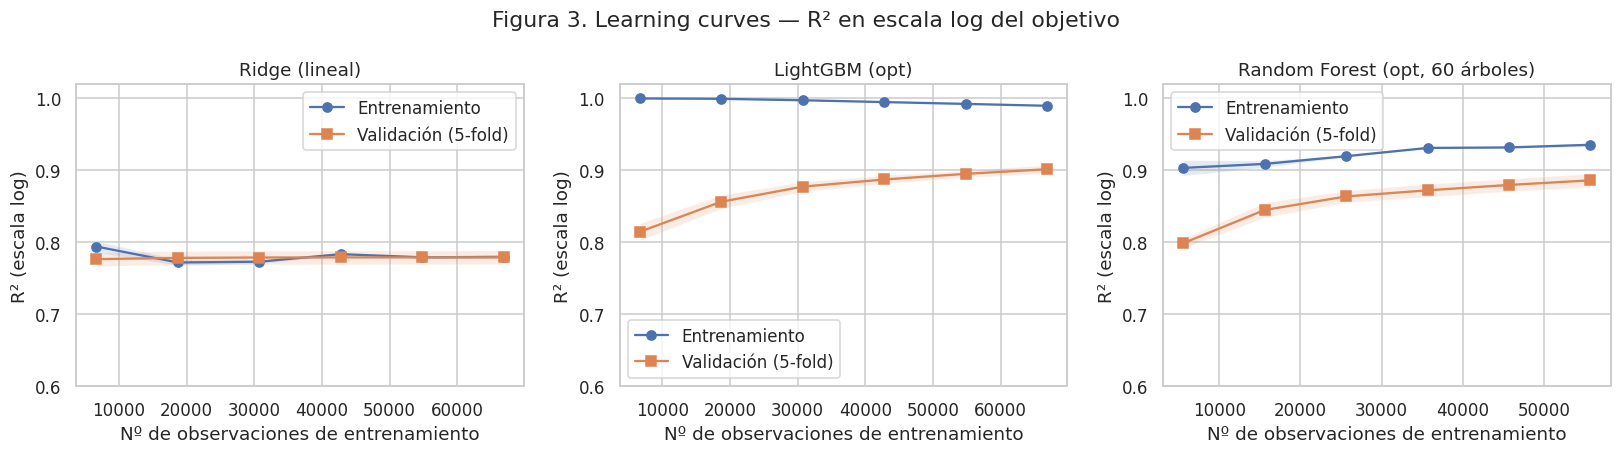

In [ ]:
def curva(modelo, nombre, ax, cv=kf, sizes=np.linspace(0.1, 1.0, 6)):
    n, tr, va = learning_curve(modelo, Xtr, y_train, cv=cv, train_sizes=sizes, scoring='r2', n_jobs=1, random_state=SEED)
    ax.plot(n, tr.mean(1), 'o-', label='Entrenamiento'); ax.fill_between(n, tr.mean(1)-tr.std(1), tr.mean(1)+tr.std(1), alpha=.15)
    ax.plot(n, va.mean(1), 's-', label='Validación (5-fold)'); ax.fill_between(n, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=.15)
    ax.set_title(nombre); ax.set_xlabel('Nº de observaciones de entrenamiento'); ax.set_ylabel('R² (escala log)'); ax.legend(); ax.set_ylim(0.6, 1.02)
    return n, tr, va

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
curva(make_pipeline(StandardScaler(), Ridge(alpha=1.0)), 'Ridge (lineal)', axes[0])
curva(lgb.LGBMRegressor(**rs_lgb.best_params_, subsample_freq=1, random_state=SEED, verbose=-1), 'LightGBM (opt)', axes[1])
rf_lc = RandomForestRegressor(**{**rs_rf.best_params_, 'n_estimators': 60}, n_jobs=-1, random_state=SEED)
curva(rf_lc, 'Random Forest (opt, 60 árboles)', axes[2], cv=KFold(3, shuffle=True, random_state=SEED))
plt.suptitle('Figura 3. Learning curves — R² en escala log del objetivo'); plt.tight_layout(); plt.show()

**Lectura de las learning curves.** El modelo lineal muestra un patrón de **underfitting**: ambas curvas convergen de inmediato a un R² de ~0,78 y agregar datos no mejora nada; el límite es la forma del modelo (lineal y aditivo), no la cantidad de datos. Los dos modelos de árboles tienen un R² de entrenamiento muy alto y una brecha con validación que **se reduce a medida que crece n** y sigue en descenso al usar el 100 % de los datos: hay sobreajuste moderado pero controlado, y la curva de validación todavía no se aplanó, lo que indica que más observaciones (más años o más departamentos) seguirían mejorando el modelo. LightGBM optimizado presenta la brecha más amplia (R² train ≈ 0,99 vs validación ≈ 0,90) porque la búsqueda seleccionó árboles complejos (`num_leaves = 255`); a pesar de ello, su R² de validación es el más alto de todos, por lo que la complejidad extra se traduce en mejor generalización y no solo en memorización.

## 4. Interpretabilidad y análisis de resultados

### 4.1 Importancia de características en los modelos basados en árboles

Se comparan las importancias de Random Forest (reducción media de impureza), LightGBM (ganancia total de las divisiones) y Gradient Boosting. Para hacer legible el gráfico, las dummies de `cultivo` y `provincia` se agregan en un solo grupo cada una.

,Random Forest (opt),LightGBM (opt),Gradient Boosting
cultivo (41 dummies),0.638,0.611,0.710
año,0.075,0.079,0.065
departamento,0.043,0.050,0.059
ratio_cosechada,0.034,0.042,0.032
log_sup_sembrada,0.053,0.040,0.035
provincia (23 dummies),0.024,0.031,0.020
log_sup_cosechada,0.026,0.029,0.015
precip_total_mm,0.020,0.024,0.014
RH2M,0.025,0.021,0.015
T2M,0.014,0.018,0.010


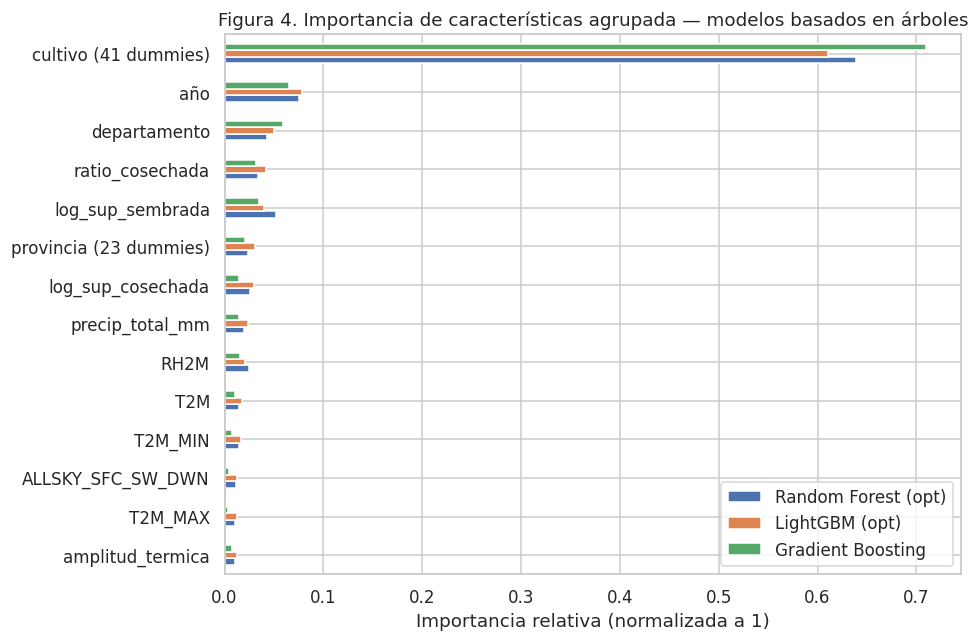

In [ ]:
def agrupar(imp, cols):
    s = pd.Series(imp, index=cols)
    g = s.copy()
    g = g[~g.index.str.startswith(('cultivo_', 'provincia_'))]
    g['cultivo (41 dummies)'] = s[s.index.str.startswith('cultivo_')].sum()
    g['provincia (23 dummies)'] = s[s.index.str.startswith('provincia_')].sum()
    return g / g.sum()

imp = pd.DataFrame({'Random Forest (opt)': agrupar(rf_opt.feature_importances_, Xtr.columns),
                    'LightGBM (opt)':      agrupar(lgb_opt.booster_.feature_importance('gain'), Xtr.columns),
                    'Gradient Boosting':   agrupar(gbr.feature_importances_, Xtr.columns)})
imp = imp.sort_values('LightGBM (opt)', ascending=True)
display(imp.sort_values('LightGBM (opt)', ascending=False).style.format('{:.3f}').background_gradient(cmap='Blues'))
imp.plot.barh(figsize=(9, 6)); plt.xlabel('Importancia relativa (normalizada a 1)')
plt.title('Figura 4. Importancia de características agrupada — modelos basados en árboles'); plt.tight_layout(); plt.show()

### 4.2 Análisis SHAP del mejor modelo (LightGBM optimizado)

SHAP (SHapley Additive exPlanations) descompone cada predicción en la contribución de cada variable, con base en la teoría de juegos. A diferencia de la importancia por impureza, es consistente, permite ver la **dirección** del efecto y detectar no linealidades. Se calcula sobre una muestra aleatoria de 4.000 observaciones del conjunto de prueba (los valores están en escala log del rendimiento).

Importancia SHAP media |φ| (agrupada, normalizada):


,SHAP
cultivo (41 dummies),0.578
año,0.095
departamento,0.057
ratio_cosechada,0.052
provincia (23 dummies),0.049
log_sup_cosechada,0.033
T2M,0.029
RH2M,0.024
precip_total_mm,0.018
log_sup_sembrada,0.016


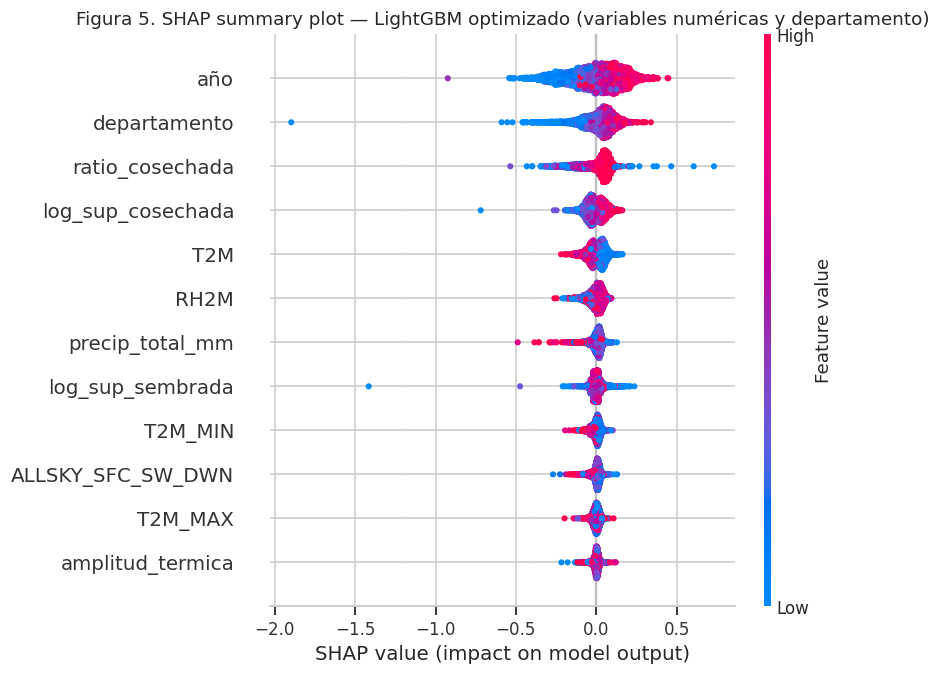

In [ ]:
mejor_nombre = 'LightGBM (opt)'; mejor = lgb_opt
Xs = Xte.sample(4000, random_state=SEED)
explainer = shap.TreeExplainer(mejor)
sv = explainer.shap_values(Xs)

# Importancia SHAP agrupada
shap_imp = agrupar(np.abs(sv).mean(0), Xs.columns).sort_values(ascending=False)
print('Importancia SHAP media |φ| (agrupada, normalizada):'); display(shap_imp.round(3).to_frame('SHAP'))

# Summary plot de variables no-dummy (las más informativas visualmente)
cols_ind = [c for c in Xs.columns if not c.startswith(('cultivo_', 'provincia_'))]
idx = [Xs.columns.get_loc(c) for c in cols_ind]
shap.summary_plot(sv[:, idx], Xs[cols_ind], show=False, max_display=14)
plt.title('Figura 5. SHAP summary plot — LightGBM optimizado (variables numéricas y departamento)'); plt.tight_layout(); plt.show()

### 4.3 Efecto de las variables climáticas: SHAP dependence plots

Cada punto es una observación; el eje y muestra cuánto suma o resta esa variable a la predicción (log-rendimiento). Estos gráficos son el equivalente local de los *partial dependence plots* y revelan la forma funcional del efecto climático.

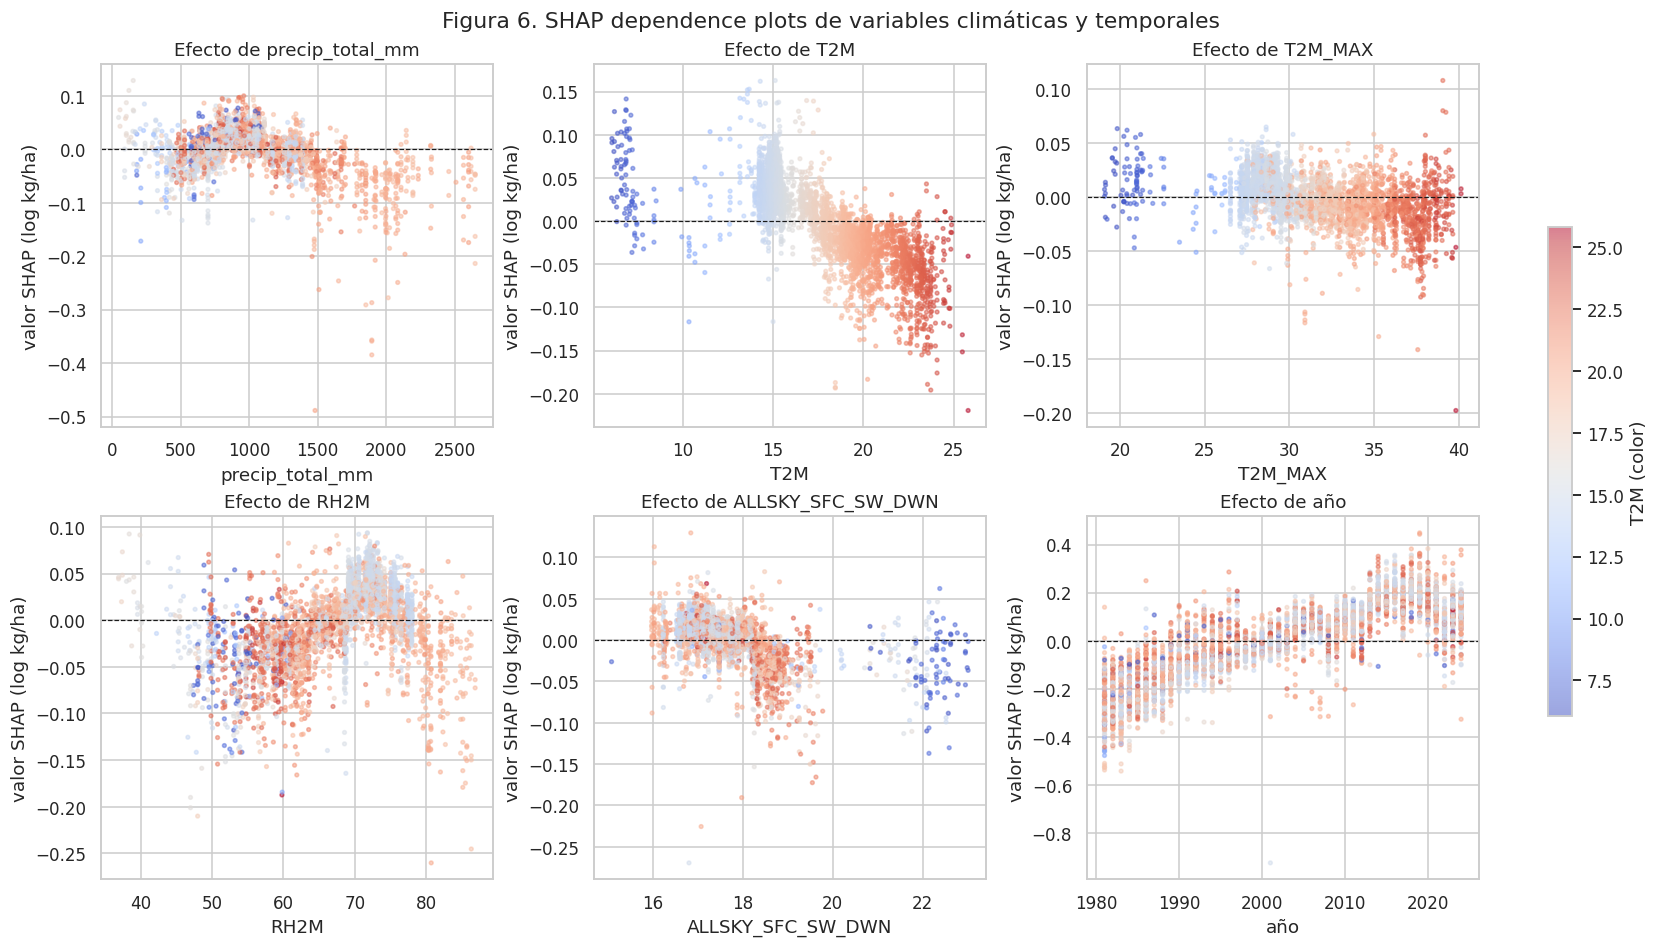

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5), constrained_layout=True); axes = axes.ravel()
for ax, c in zip(axes, ['precip_total_mm', 'T2M', 'T2M_MAX', 'RH2M', 'ALLSKY_SFC_SW_DWN', 'año']):
    j = Xs.columns.get_loc(c)
    sc = ax.scatter(Xs[c], sv[:, j], c=Xs['T2M'], cmap='coolwarm', s=6, alpha=.5)
    ax.axhline(0, color='k', lw=.8, ls='--'); ax.set_xlabel(c); ax.set_ylabel('valor SHAP (log kg/ha)'); ax.set_title(f'Efecto de {c}')
fig.colorbar(sc, ax=axes.tolist(), label='T2M (color)', shrink=.6)
fig.suptitle('Figura 6. SHAP dependence plots de variables climáticas y temporales'); plt.show()

### 4.4 Variables climáticas y geográficas con mayor impacto

Para responder explícitamente qué determina el rendimiento, se resume la importancia SHAP por **grupo de variables**.

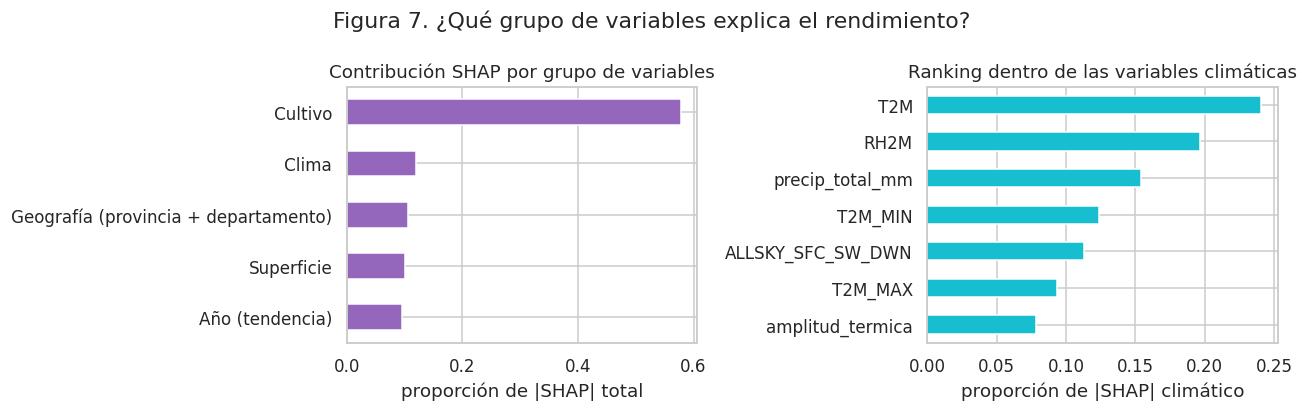

,Por grupo,Dentro de clima
Cultivo,0.578,
Geografía (provincia + departamento),0.106,
Clima,0.120,
Superficie,0.101,
Año (tendencia),0.095,
T2M,,0.241
RH2M,,0.197
precip_total_mm,,0.154
T2M_MIN,,0.124
ALLSKY_SFC_SW_DWN,,0.113


In [ ]:
grupos = {'Cultivo': [c for c in Xs.columns if c.startswith('cultivo_')],
          'Geografía (provincia + departamento)': [c for c in Xs.columns if c.startswith('provincia_')] + ['departamento'],
          'Clima': CLIMA, 'Superficie': ['log_sup_sembrada', 'log_sup_cosechada', 'ratio_cosechada'], 'Año (tendencia)': ['año']}
abs_sv = pd.Series(np.abs(sv).mean(0), index=Xs.columns)
por_grupo = pd.Series({g: abs_sv[c].sum() for g, c in grupos.items()}); por_grupo = por_grupo / por_grupo.sum()
clima_det = (abs_sv[CLIMA] / abs_sv[CLIMA].sum()).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
por_grupo.sort_values().plot.barh(ax=ax[0], color='tab:purple'); ax[0].set_title('Contribución SHAP por grupo de variables'); ax[0].set_xlabel('proporción de |SHAP| total')
clima_det.sort_values().plot.barh(ax=ax[1], color='tab:cyan'); ax[1].set_title('Ranking dentro de las variables climáticas'); ax[1].set_xlabel('proporción de |SHAP| climático')
plt.suptitle('Figura 7. ¿Qué grupo de variables explica el rendimiento?'); plt.tight_layout(); plt.show()
display(pd.concat([por_grupo.rename('Por grupo'), clima_det.rename('Dentro de clima')], axis=1).style.format('{:.3f}', na_rep=''))

### 4.5 Análisis de residuos del mejor modelo

Se verifican los supuestos habituales sobre los residuos (en escala log, que es donde el modelo fue entrenado): media cero, ausencia de patrón respecto a la predicción (homocedasticidad), distribución aproximadamente simétrica, y error comparable entre cultivos.

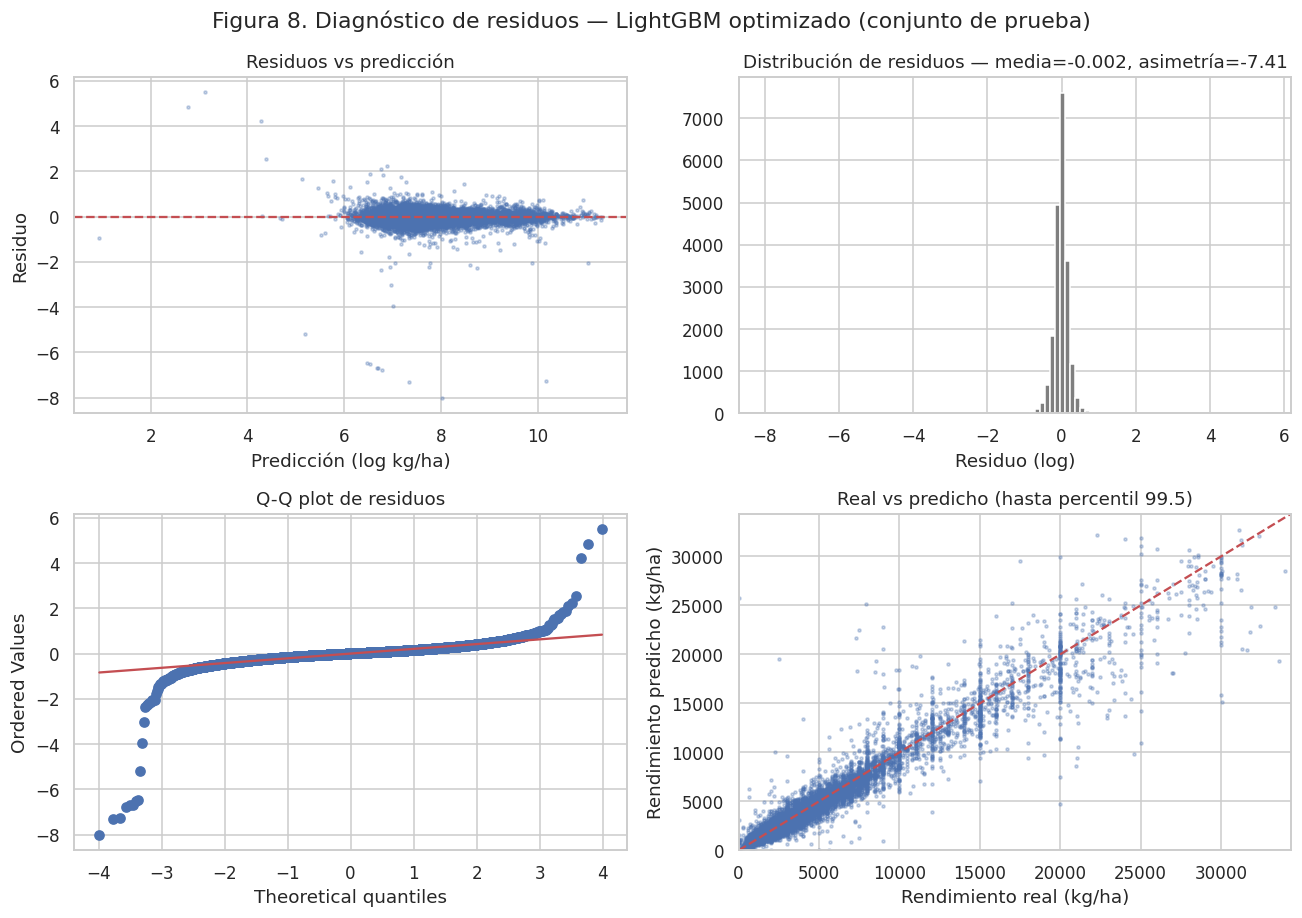

Error por cultivo (10 mejores y 10 peores en MAE relativo):


,n,rend_medio,MAE,MAE relativo (%)
cultivo,,,,
arroz,291,"5,358",455,8.5
banana,38,"14,922","1,322",8.9
ajo,326,"4,999",501,10.0
té,152,"7,091",722,10.2
tung,86,"1,900",199,10.5
soja 1ra,1290,"2,526",272,10.8
soja total,2035,"2,209",238,10.8
poroto alubia,12,"1,345",149,11.0
mandarina,236,"11,987","1,392",11.6


In [ ]:
pred_log = mejor.predict(Xte); res = y_test - pred_log
fig, ax = plt.subplots(2, 2, figsize=(12, 8.5))
ax[0,0].scatter(pred_log, res, s=4, alpha=.3); ax[0,0].axhline(0, color='r', ls='--'); ax[0,0].set_xlabel('Predicción (log kg/ha)'); ax[0,0].set_ylabel('Residuo'); ax[0,0].set_title('Residuos vs predicción')
ax[0,1].hist(res, bins=100, color='tab:gray'); ax[0,1].set_xlabel('Residuo (log)'); ax[0,1].set_title(f'Distribución de residuos — media={res.mean():.3f}, asimetría={res.skew():.2f}')
from scipy import stats
stats.probplot(res, dist='norm', plot=ax[1,0]); ax[1,0].set_title('Q-Q plot de residuos')
yt, yp = np.expm1(y_test), np.expm1(pred_log)
ax[1,1].scatter(yt, yp, s=4, alpha=.3); lim = [0, np.percentile(yt, 99.5)]; ax[1,1].plot(lim, lim, 'r--'); ax[1,1].set_xlim(lim); ax[1,1].set_ylim(lim)
ax[1,1].set_xlabel('Rendimiento real (kg/ha)'); ax[1,1].set_ylabel('Rendimiento predicho (kg/ha)'); ax[1,1].set_title('Real vs predicho (hasta percentil 99.5)')
plt.suptitle('Figura 8. Diagnóstico de residuos — LightGBM optimizado (conjunto de prueba)'); plt.tight_layout(); plt.show()

err = pd.DataFrame({'cultivo': X_test['cultivo'].values, 'real': yt.values, 'abs_err': np.abs(yt.values - yp)})
por_cult = err.groupby('cultivo').agg(n=('real', 'size'), rend_medio=('real', 'mean'), MAE=('abs_err', 'mean'))
por_cult['MAE relativo (%)'] = por_cult['MAE'] / por_cult['rend_medio'] * 100
print('Error por cultivo (10 mejores y 10 peores en MAE relativo):')
display(pd.concat([por_cult.nsmallest(10, 'MAE relativo (%)'), por_cult.nlargest(10, 'MAE relativo (%)')]).style.format({'rend_medio':'{:,.0f}','MAE':'{:,.0f}','MAE relativo (%)':'{:.1f}'}))

**Lectura.** Los residuos están centrados en cero y no muestran una tendencia sistemática respecto a la predicción, aunque la dispersión es mayor en predicciones bajas (cultivos de bajo rendimiento y cosechas parciales, donde un mismo error absoluto pesa más en escala log). El Q-Q plot muestra colas más pesadas que una normal, típico de datos agrícolas con eventos extremos (sequías, heladas, inundaciones) que el clima anual promedio no logra explicar. El error relativo por cultivo es heterogéneo: los cultivos extensivos con muchas observaciones se predicen mejor que los regionales o poco frecuentes.

## 5. Comparativa final de modelos

### 5.1 Tabla resumen de todas las métricas

In [ ]:
final = pd.DataFrame(resultados).T
final['R² CV (5-fold)'] = pd.Series({k: v['R² CV media'] for k, v in cv_res.items()})
final['± desvío CV']    = pd.Series({k: v['R² CV desvío'] for k, v in cv_res.items()})
final = final.sort_values('R² test', ascending=False)
fmt = {c: '{:,.0f}' for c in ['MAE train','RMSE train','MAE test','RMSE test']}
fmt.update({'R² train':'{:.4f}','R² test':'{:.4f}','Tiempo (s)':'{:.1f}','R² CV (5-fold)':'{:.4f}','± desvío CV':'{:.4f}'})
display(final.style.format(fmt).background_gradient(subset=['R² test','R² CV (5-fold)'], cmap='Greens').background_gradient(subset=['MAE test','RMSE test'], cmap='Reds_r'))

,MAE train,RMSE train,R² train,MAE test,RMSE test,R² test,Tiempo (s),R² CV (5-fold),± desvío CV
LightGBM (opt),211,877,0.9731,500,"1,276",0.9419,7.0,0.9011,0.0053
Random Forest,262,"1,116",0.9564,484,"1,280",0.9416,104.9,0.9000,0.0072
Random Forest (opt),378,"1,343",0.9368,526,"1,366",0.9335,47.4,0.8908,0.0087
LightGBM,538,"1,518",0.9193,602,"1,430",0.9270,4.2,0.8873,0.0070
Gradient Boosting,748,"1,822",0.8838,775,"1,693",0.8978,52.5,0.8410,0.0068
Regresión Lineal,"1,023","2,470",0.7864,"1,020","2,243",0.8205,0.4,0.7793,0.0095
Ridge,"1,023","2,470",0.7864,"1,020","2,243",0.8205,0.1,0.7793,0.0095


### 5.2 Gráficos comparativos con barras de error (validación cruzada)

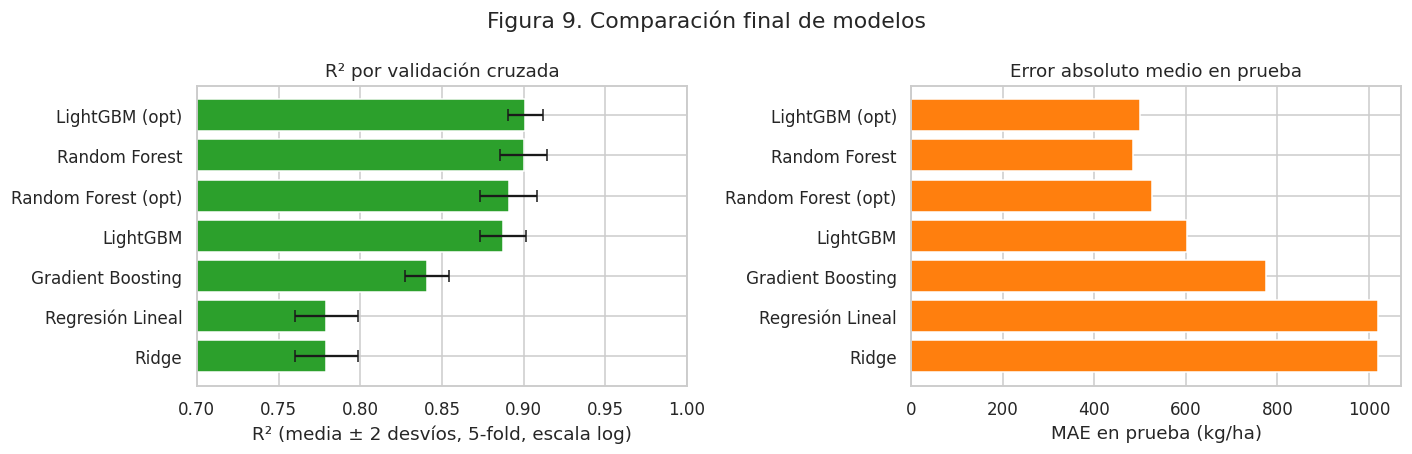

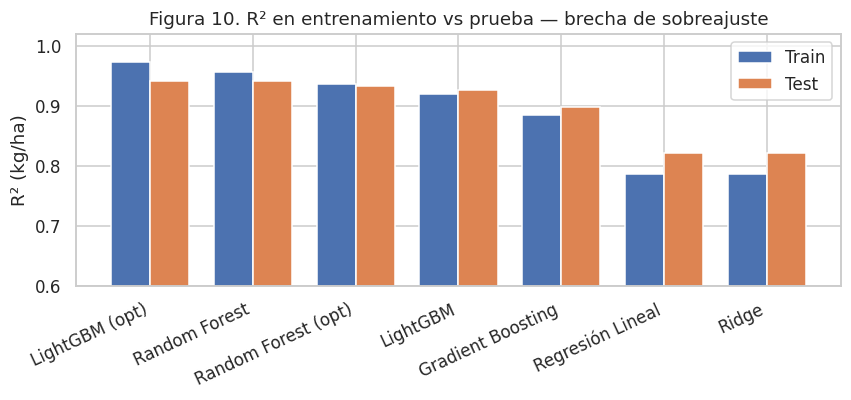

In [ ]:
orden = final.index
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].barh(orden, [cv_res[m]['R² CV media'] for m in orden], xerr=[cv_res[m]['R² CV desvío']*2 for m in orden], color='tab:green', capsize=4)
ax[0].set_xlim(0.7, 1.0); ax[0].set_xlabel('R² (media ± 2 desvíos, 5-fold, escala log)'); ax[0].set_title('R² por validación cruzada'); ax[0].invert_yaxis()
ax[1].barh(orden, final.loc[orden, 'MAE test'], color='tab:orange'); ax[1].set_xlabel('MAE en prueba (kg/ha)'); ax[1].set_title('Error absoluto medio en prueba'); ax[1].invert_yaxis()
plt.suptitle('Figura 9. Comparación final de modelos'); plt.tight_layout(); plt.show()

# Test vs Train para visualizar sobreajuste
fig, ax = plt.subplots(figsize=(8, 3.8))
w = 0.38; x = np.arange(len(orden))
ax.bar(x - w/2, final.loc[orden, 'R² train'], w, label='Train'); ax.bar(x + w/2, final.loc[orden, 'R² test'], w, label='Test')
ax.set_xticks(x); ax.set_xticklabels(orden, rotation=25, ha='right'); ax.set_ylim(0.6, 1.02); ax.set_ylabel('R² (kg/ha)'); ax.legend()
ax.set_title('Figura 10. R² en entrenamiento vs prueba — brecha de sobreajuste'); plt.tight_layout(); plt.show()

### 5.3 Matriz de correlación entre las predicciones de los modelos

Mide cuán parecidas son las predicciones de cada par de modelos sobre el conjunto de prueba. Correlaciones muy altas indican que los modelos "ven" lo mismo (poco margen para un *ensemble* de ellos); correlaciones más bajas señalan familias de modelos que capturan patrones distintos.

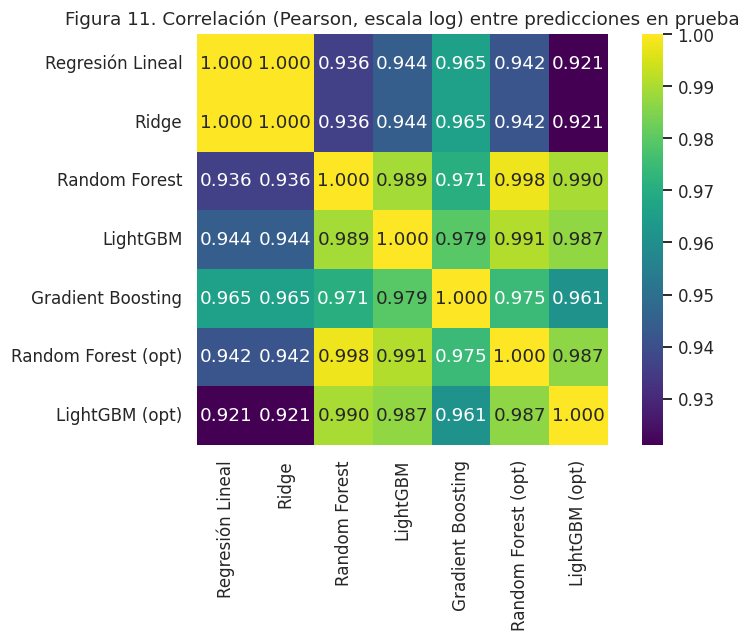

In [ ]:
P = pd.DataFrame(preds_test)
corr = np.log1p(P.clip(lower=0)).corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='viridis', vmin=corr.values.min(), ax=ax, square=True)
ax.set_title('Figura 11. Correlación (Pearson, escala log) entre predicciones en prueba'); plt.tight_layout(); plt.show()

**Lectura de la matriz.** Todas las predicciones están altamente correlacionadas (la variable `cultivo` domina el nivel del rendimiento y todos los modelos la capturan). Las correlaciones más bajas aparecen entre los modelos lineales y los de árboles, confirmando que estos últimos aprenden interacciones y no linealidades que la regresión lineal no puede representar. Entre Random Forest y LightGBM optimizado la correlación es la más alta: ambos "ven" prácticamente lo mismo, por lo que un *ensemble* entre ellos aportaría poca ganancia adicional.

## 6. Conclusión final del modelado supervisado

### 6.1 Modelo ganador: LightGBM optimizado

| Criterio | LightGBM (opt) | Random Forest (inicial) | Regresión Lineal (base) |
|---|---|---|---|
| R² en prueba (kg/ha) | **0,942** | 0,942 | 0,821 |
| MAE en prueba | 500 kg/ha | **484 kg/ha** | 1.020 kg/ha |
| RMSE en prueba | **1.276 kg/ha** | 1.280 kg/ha | 2.243 kg/ha |
| R² validación cruzada 5-fold (log) | **0,901 ± 0,005** | 0,900 ± 0,007 | 0,779 ± 0,010 |
| Tiempo de entrenamiento | **7 s** | 105 s | 0,4 s |

Random Forest y LightGBM optimizado empatan técnicamente en el conjunto de prueba (la diferencia de R² es de 0,0003 y la de MAE de 16 kg/ha, ambas dentro del desvío de la validación cruzada). Se elige **LightGBM optimizado** como modelo ganador por tres razones:

1. **Mejor y más estable en validación cruzada**: tiene el R² CV más alto y el menor desvío entre folds de los siete modelos, es decir, el desempeño menos dependiente de la partición particular.
2. **15 veces más rápido** que Random Forest con igual precisión, lo que lo hace práctico para reentrenar cada campaña, hacer búsquedas de hiperparámetros más amplias o desplegarlo en producción.
3. **Mejor soporte para interpretabilidad** (SHAP se calcula de forma exacta y eficiente sobre boosting) y manejo nativo de valores faltantes, relevante para variables climáticas con cobertura incompleta.

Respecto al modelo base, el ganador **reduce el MAE en un 51 %** (de 1.020 a 500 kg/ha) y **eleva el R² de 0,82 a 0,94**. Un dato a destacar: la optimización de Random Forest sobre la submuestra de 30.000 filas seleccionó hiperparámetros más regularizados (`min_samples_leaf = 4`) que resultaron levemente peores al reentrenar con los 83.558 datos completos; con más datos, los árboles profundos del bagging se benefician de menos regularización. Es un recordatorio de que los hiperparámetros óptimos dependen del tamaño muestral.

### 6.2 Hallazgos clave: qué determina el rendimiento

Según el análisis SHAP del modelo ganador (sección 4.4):

- **El tipo de cultivo explica el 58 % de la variabilidad** del rendimiento. Es esperable: la caña de azúcar rinde 36.000 kg/ha y el cártamo 700 kg/ha por su biología, no por el clima.
- **La tendencia temporal (`año`) es el segundo factor individual (9,5 %)** y su efecto es claramente creciente (Figura 6): el rendimiento de un mismo cultivo en el mismo lugar sube sostenidamente desde 1981, reflejando el progreso genético, la siembra directa, la fertilización y la tecnología de manejo. Este efecto es mayor que el de cualquier variable climática individual.
- **El clima aporta el 12 % en conjunto**, con este orden de importancia: temperatura media (`T2M`, 24 % del efecto climático), humedad relativa (`RH2M`, 20 %), precipitación anual (15 %), temperatura mínima (12 %), radiación (11 %), temperatura máxima (9 %) y amplitud térmica (8 %). Las formas funcionales son coherentes con la agronomía:
  - `T2M`: efecto positivo por debajo de ~17 °C y **negativo creciente por encima de ~20 °C** (estrés térmico en regiones cálidas del NOA/NEA).
  - `precip_total_mm`: **óptimo entre 800 y 1.100 mm anuales**; tanto años secos (< 600 mm) como muy húmedos (> 1.500 mm, anegamiento y enfermedades) penalizan el rendimiento.
  - `RH2M`: efecto negativo con humedad baja (< 60 %, ambientes semiáridos) y positivo entre 65 y 75 %.
- **La geografía (provincia + departamento) suma el 10,6 %**: captura calidad de suelo, infraestructura y prácticas regionales que el clima anual no describe. El target encoding de `departamento` resultó más informativo que las 23 dummies de provincia, lo que confirma que la heterogeneidad relevante es a escala departamental.
- **La superficie (10 %)**, especialmente `ratio_cosechada`: una baja proporción cosechada/sembrada anticipa rendimientos bajos (lotes perdidos por sequía, inundación o helada) y es la señal más directa de una campaña adversa disponible en el dataset.

### 6.3 Limitaciones del modelo en el contexto agrícola argentino

1. **Clima anual, no estacional.** Las variables climáticas son promedios de 12 meses. El rendimiento de un cultivo depende de lo que ocurre en ventanas críticas (floración del maíz en enero, llenado de grano del trigo en octubre–noviembre). Una sequía de 40 días en enero puede destruir la campaña de maíz sin alterar apreciablemente la precipitación anual. Esta es la principal razón por la que el clima aparece con un peso menor al esperado y por la que persisten colas pesadas en los residuos.
2. **Sin variables de suelo ni de manejo.** No hay información de tipo de suelo, napa, fertilización, riego, genética ni fecha de siembra. Todo esto queda absorbido de forma indirecta por `departamento` y `año`, lo que limita la capacidad de extrapolar a condiciones nuevas.
3. **Validación aleatoria, no temporal.** El split 80/20 mezcla años: el modelo "conoce" 2015 al predecir 2016 en el mismo departamento. Para un uso real de pronóstico, la evaluación debería ser temporal (entrenar hasta el año *t*, probar en *t+1*), y es probable que el R² baje.
4. **Fuga parcial por `superficie_cosechada_ha` y `ratio_cosechada`.** Estas variables solo se conocen al final de la campaña, por lo que el modelo es útil para **estimar** y **explicar** rendimientos, no para pronosticarlos antes de la cosecha. Un modelo de pronóstico anticipado debería excluirlas (con pérdida de precisión).
5. **Calidad heterogénea de los datos oficiales.** Los rendimientos departamentales son estimaciones de delegaciones del ministerio; hay valores extremos (por ejemplo, 300.000 kg/ha de cebolla) que probablemente sean errores de carga, y cultivos con muy pocas observaciones (poroto alubia: 12 en prueba) donde el error relativo es alto.
6. **Cultivos agregados** (`soja total`, `trigo total`) mezclan primera y segunda ocupación, con rendimientos estructuralmente distintos.

### 6.4 Recomendaciones prácticas para productores

Los resultados son de nivel departamental y no reemplazan el asesoramiento agronómico a escala de lote, pero permiten algunas recomendaciones generales:

- **Priorizar la incorporación de tecnología.** El efecto del año (progreso tecnológico) supera al de cualquier variable climática: la brecha de rendimiento asociada al nivel tecnológico es, según el modelo, más grande que la brecha entre un año climáticamente bueno y uno regular. Genética actualizada, fertilización balanceada y siembra directa son las palancas de mayor retorno.
- **Gestionar el riesgo térmico en regiones cálidas.** En departamentos con temperatura media anual > 20 °C (NOA, NEA, norte de Santa Fe y Córdoba), el modelo asigna una penalización sistemática. Conviene ajustar fechas de siembra para escapar del estrés térmico en floración, elegir cultivares tolerantes al calor y, donde sea posible, incorporar riego suplementario.
- **En zonas semiáridas (precipitación < 600 mm), el agua es el límite**: rotaciones con barbecho, cultivos de cobertura para retener humedad, siembra directa y, en girasol, sorgo o maní, aprovechar su mayor tolerancia al déficit hídrico frente a maíz o soja.
- **En zonas muy húmedas (> 1.500 mm, litoral), atender el drenaje y la sanidad**: el modelo muestra penalización por exceso de agua, asociada a anegamiento y presión de enfermedades fúngicas; drenaje, elección de lotes altos y monitoreo sanitario son las respuestas.
- **Usar el modelo como referencia comparativa (benchmark)**: un productor puede contrastar su rendimiento con la predicción para su cultivo, departamento y año; una diferencia negativa persistente sugiere un problema de manejo o suelo que vale la pena diagnosticar.

### 6.5 Propuestas de mejora para trabajo futuro

1. **Variables climáticas mensuales o por etapa fenológica** (NASA POWER las ofrece): precipitación y temperatura de los meses críticos de cada cultivo, número de días con temperatura máxima > 35 °C, balance hídrico acumulado. Es la mejora de mayor impacto esperado.
2. **Validación temporal** (*rolling origin*): entrenar con 1981–2018, validar en 2019–2024, para medir la capacidad real de pronóstico.
3. **Incorporar variables de suelo** (INTA: capacidad de uso, materia orgánica, profundidad) y de manejo (fertilización, riego, uso de semilla certificada de los censos agropecuarios).
4. **Modelos por familia de cultivos** (cereales, oleaginosas, frutales, industriales): cada uno con su propio conjunto de hiperparámetros y sus ventanas climáticas críticas, probablemente superando al modelo único.
5. **Índices de vegetación satelitales** (NDVI de MODIS/Sentinel) como predictores intra-campaña, que permitirían un pronóstico anticipado del rendimiento sin depender de `superficie_cosechada_ha`.
6. **Modelos de efectos mixtos o de series temporales** que traten explícitamente la estructura departamento × año, y **cuantificación de incertidumbre** (regresión por cuantiles con LightGBM o intervalos conformales) para entregar rangos de rendimiento y no solo un valor puntual.
7. **Búsqueda de hiperparámetros más amplia** (optimización bayesiana con Optuna) sobre el conjunto completo y con validación temporal, dado que se comprobó que los óptimos hallados en submuestra no se trasladan perfectamente a todos los datos.